<a id="chapter-10"></a>

# Chapter 10 · Stocks Trading Using RL / 用 RL 做股票交易

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 把价格序列建模为环境
- 理解收益、仓位与交易成本
- 避免时间泄漏和不现实评估

**开始前最好已经会：**

- 理解 Gym 环境建模
- 知道简单收益和复利
- 会做按时间切分的数据实验


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Why trading / problem decisions | 状态、动作、奖励定义 | 详细 |
| Data | OHLC 读取、切分、特征 | 源码精读 |
| Trading environment | 记账与终止 | 详细 |
| Models | feed-forward / convolution | 结构对比 |
| Training code | 端到端流程 | 完整 |
| Results: feed-forward / convolution | 评估解读 | 详细 |
| Things to try | 练习与扩展 | 实践 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

一个回测赚钱，是策略真的学到了规律，还是偷看未来、忽略成本或记账出错？交易环境首先是数据与评估问题。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

观测只能含当前及过去信息；动作决定仓位；奖励应反映净值变化并扣除成本。重点是正确评估，不是把训练收益当作可交易结论。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $p_t$ | 时刻 $t$ 的价格 | 观测只能使用当时可知值 |
| $h_t$ | 区间 $[t,t+1)$ 的仓位 | 正/零/负表示多仓/空仓/空头 |
| $r_t$ | 资产收益 | 价格相对变化 |
| $c$ | 单位换仓成本 | 手续费、点差、滑点近似 |
| equity | 累计净值 | 逐步奖励复合后的结果 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从价格到可加的奖励

简单收益为 $(p_{t+1}-p_t)/p_t$。对数收益

$$\ell_t=\log p_{t+1}-\log p_t=\log(p_{t+1}/p_t)$$

具有可加性：$\sum_t\ell_t=\log(p_T/p_0)$，适合作为逐步奖励。

### 2. 仓位怎样影响收益

在区间 $[t,t+1)$ 持有仓位 $h_t$，忽略杠杆细节时毛收益近似 $h_t\ell_t$。从 $h_{t-1}$ 换到 $h_t$ 产生交易量 $|h_t-h_{t-1}|$，所以

$$R_{t+1}=h_t\ell_t-c|h_t-h_{t-1}|$$

注意时间顺序：先根据时刻 $t$ 可见信息决定 $h_t$，再获得 $t\to t+1$ 的收益。

### 3. 为什么不能随机划分数据

市场分布随时间变化，特征窗口也含相邻数据。随机划分会让未来时期进入训练集，甚至让高度重叠的窗口分到训练和测试两侧。正确顺序是 train → validation → test，并只在训练集拟合标准化参数。


## 4. 手算一个最小例子


价格从 100 到 102，对数收益约 $\log(1.02)=0.0198$。若从空仓换到多仓，$c=0.001$，该步净奖励约 $0.0188$。

若下一步仍持多仓，不再支付换仓成本；若从 +1 直接换到 -1，交易量是 2，成本是 $2c$，不是 $c$。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 交易回报

简单收益 $r_t=(p_{t+1}-p_t)/p_t$，对数收益 $\ell_t=\log(p_{t+1}/p_t)$。

若仓位 $h_t\in\{-1,0,1\}$，一种简化奖励为：
$$R_{t+1}=h_t\ell_t-c|h_t-h_{t-1}|$$

$c$ 同时近似手续费与滑点。训练/验证/测试必须按时间切分；随机打乱会把未来信息泄漏到过去。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $\ell_t$ | `np.diff(np.log(prices))` | 每个相邻价格区间一个值 |
| $h_t$ | `positions` | 长度与收益区间相同 |
| $h_{t-1}$ | `np.r_[0., positions[:-1]]` | 初始假设空仓 |
| 换仓成本 | `cost_rate * abs(position - previous)` | 仓位变化绝对值 |
| 累计净值 | `np.exp(np.cumsum(rewards))` | 对数奖励还原成净值倍数 |

**从公式过渡到代码时：**用合成价格展示持仓收益与换仓成本。这里不是投资策略，只用于验证环境记账。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np

prices = np.array([100., 102., 101., 104., 103.])
positions = np.array([0., 1., 1., -1.])  # 区间 [t, t+1) 的仓位
log_returns = np.diff(np.log(prices))
previous_positions = np.r_[0., positions[:-1]]
cost_rate = 0.001
rewards = positions * log_returns - cost_rate * np.abs(positions - previous_positions)
equity = np.exp(np.cumsum(rewards))
print("step rewards:", np.round(rewards, 5))
print("equity multiplier:", np.round(equity, 5))


step rewards: [ 0.      -0.01085  0.02927  0.00766]
equity multiplier: [1.      0.98921 1.01859 1.02642]


### 怎样读运行结果

检查每一步奖励，而不只看最终净值。示例中换仓时出现成本扣减；从多头切到空头成本最大。这个逐步审计应成为交易环境的单元测试。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
按时间加载 OHLC 数据 → 只用训练期拟合预处理
env.reset: 选择起点、清空仓位与收益
每一步：
  obs = 最近 bars 特征 + 当前仓位
  action ∈ {skip, buy, close}（以仓库定义为准）
  根据价格变化更新持仓 PnL
  若仓位改变，扣 commission
  到达窗口末尾/破产/数据末尾则结束
DQN 收集 replay 并训练；定期在独立验证区间评估
最终只在从未用于选择模型的测试区间报告结果
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# 时间切分：任何 rolling 特征都只能向过去看。
prices = np.arange(20.0)
train, valid, test = prices[:12], prices[12:16], prices[16:]
train_mean = train.mean()
print("ranges:", (train[0], train[-1]), (valid[0], valid[-1]), (test[0], test[-1]))
print("train-only mean:", train_mean, "leaky all-data mean:", prices.mean())
assert train[-1] < valid[0] < test[0]


ranges: (0.0, 11.0) (12.0, 15.0) (16.0, 19.0)
train-only mean: 5.5 leaky all-data mean: 9.5


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`data.py`](../../Chapter10/lib/data.py) | 价格读取与 `Prices` 数据 | 先确认字段和时间顺序 |
| [`environ.py`](../../Chapter10/lib/environ.py) | `State`, `StocksEnv` | 逐步审计观测、reward、commission |
| [`models.py`](../../Chapter10/lib/models.py) | 前馈/卷积模型 | 比较输入 shape 与 receptive field |
| [`validation.py`](../../Chapter10/lib/validation.py) | 验证函数 | 区分训练 reward 与回测指标 |
| [`train_model.py`](../../Chapter10/train_model.py) | 训练入口 | 数据切分、env、DQN 配置 |
| [`test_environ.py`](../../Chapter10/tests/test_environ.py) | 环境测试 | 记账逻辑的可执行规范 |

<details>
<summary>为什么按这个顺序读</summary>

先读测试再读环境：测试能告诉你作者认为什么是正确的 price move、position 和 reward。特别核对动作发生在 bar 的哪个价格、commission 在开仓还是平仓扣除、观测窗口是否包含下一根 bar。模型部分最后读，因为错误记账无法靠更强网络弥补。书中卷积模型只是改变时间特征提取，不解决非平稳、成本和数据泄漏。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**扣除交易成本后的 episode PnL

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


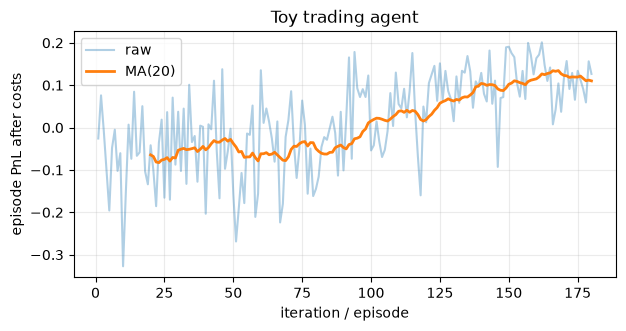

policy [down, flat, up]: [ 1 -1  1] last-20 PnL: 0.11016159238066063


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(10)
returns_pattern = np.array([.02, .01, -.015, -.02, .012, .018, -.01, .006])
q = np.zeros((3, 3))  # state: down/flat/up, action: short/flat/long
pnl_history = []
for episode in range(180):
    returns = np.resize(np.roll(returns_pattern, episode % len(returns_pattern)), 64)
    returns = returns + rng.normal(0, .004, 64)
    position, total = 1, 0.0
    for t in range(len(returns) - 1):
        state = int(np.sign(returns[t])) + 1
        action = rng.integers(3) if rng.random() < max(.05, 1 - episode / 130) else np.argmax(q[state])
        cost = .002 * (action != position)
        reward = (action - 1) * returns[t + 1] - cost
        next_state = int(np.sign(returns[t + 1])) + 1
        q[state, action] += .12 * (reward + .9 * q[next_state].max() - q[state, action])
        position, total = action, total + reward
    pnl_history.append(total)

plot_curve(pnl_history, "Toy trading agent", "episode PnL after costs", window=20)
print("policy [down, flat, up]:", q.argmax(axis=1) - 1, "last-20 PnL:", np.mean(pnl_history[-20:]))


### 曲线怎么读

应看扣费后 PnL 的移动平均、波动和换手率，而非只看训练 loss。若无费用时盈利、加入费用后转负，说明策略学到的是频繁交易而非稳健信号。

### 调参过程：一次只改变一个因素

- 先固定时间切分和 buy-and-hold 基线，禁止随机打乱未来数据。
- 先调 reward/交易成本和 observation，再调网络与学习率。
- 只在验证集选择超参数，最终测试集只使用一次。

### 失败案例复盘

- 归一化使用了未来数据，造成 look-ahead leakage。
- 训练和测试跨越同一时间窗口，成绩虚高。
- 忽略手续费、滑点和持仓约束，策略不可执行。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 先用手算轨迹测试 cash、position、commission，再开始训练。
- 标准化参数只能在训练集估计。
- 报告最大回撤、换手率和成本敏感性，不能只报平均回报。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把成本改为 0、0.001、0.01，比较最终净值；解释频繁换仓为何在高成本下失败。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

成本为 0 时只计算仓位乘价格收益；0.001 时每次换仓扣费；0.01 时频繁换仓很可能吞掉所有优势。应打印每步 `gross_return`、`turnover_cost` 和 `net_reward`，确认差值精确等于成本项。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 动作、持仓和收益区间的时间对齐最重要。
- 交易成本与仓位变化量相关。
- 训练/验证/测试必须按时间顺序。
- 教学回测不等于可部署投资策略。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么从仓位 +1 变成 -1 的成本按 2 计算？标准化均值能否用全部数据估计？

<details>
<summary>展开答案</summary>

仓位变化绝对值是 $|-1-1|=2$，相当于先平多仓再开空仓。标准化参数只能用训练期估计，否则泄漏未来分布信息。
</details>


## 17. 与前后章节连接

第 11 章转入策略方法；交易环境也可用 actor-critic，但数据泄漏和评估原则完全不变。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

真实回测还需考虑 bid-ask spread、成交量、延迟、企业行动、幸存者偏差和风险约束；这超出本章教学环境。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-10) · [← 学习索引](../README.md)
